# 05 · GME detection with the N×(N+N mod 2)/2×1 ANN
**Paper:** Sec. III A (Fig. 1a), Sec. IV C, Table V  
Sigmoid output $p_0$; a state is GME if $p_0\ge0.5$. Training set: 8×10³ non-GME, 4×10³ GME.  
**Code:** `ann_entanglement.models`, `ann_entanglement.experiments` (re-implementation)

In [1]:
import os, sys
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
sys.path.insert(0, os.path.abspath("../src"))  # not needed after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)

In [2]:
from ann_entanglement import experiments
train, exp_x = experiments.prepare(n_per_class=2000, seed=0)
train['gme'].value_counts()

gme
0    8000
1    4000
Name: count, dtype: int64

Quick demo: the paper's optimal 4×2×1 model on 3 splits.

In [3]:
experiments.ann_sweep('gme', train, exp_x, n_values=[4], n_splits=3)

I0000 00:00:1795432119.806812   18836 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795432121.100293   18836 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


,N,network,features,mu_Av,sd_Av,mu_Lv,sd_Lv,mu_At,sd_At,mu_Lt,sd_Lt,A_T,sd_AT,acc_all30
0,4,4x2x1,"Re_rho_07, Re_rho_56, Re_rho_06, Re_rho_05",0.926,0.052,0.314,0.049,0.917,0.068,0.315,0.059,0.922,0.042,0.922


,N,network,mu_Av,sd_Av,mu_Lv,sd_Lv,mu_At,sd_At,mu_Lt,sd_Lt,A_T,sd_AT,acc_all30,A1_svm,A2_knn
0,1,1x1x1,0.817,0.050,0.533,0.041,0.817,0.050,0.531,0.043,0.817,5.000e-02,0.817,0.833,0.400
1,2,2x1x1,0.867,0.044,0.391,0.038,0.883,0.067,0.347,0.049,0.873,4.163e-02,0.873,0.900,0.533
2,3,3x2x1,0.867,0.027,0.307,0.026,0.900,0.050,0.261,0.039,0.880,1.633e-02,0.880,0.933,0.767
3,4,4x2x1,0.956,0.042,0.305,0.033,0.967,0.055,0.293,0.046,0.960,3.590e-02,0.960,0.967,0.900
4,5,5x3x1,0.939,0.017,0.265,0.020,0.983,0.050,0.238,0.056,0.957,2.134e-02,0.957,0.900,0.967
5,6,6x3x1,0.928,0.025,0.274,0.022,0.942,0.084,0.250,0.067,0.933,3.944e-02,0.933,0.900,0.967
6,7,7x4x1,0.939,0.030,0.258,0.023,0.950,0.067,0.238,0.061,0.943,3.000e-02,0.943,0.900,0.967
7,8,8x4x1,0.944,0.025,0.233,0.019,0.983,0.033,0.215,0.056,0.960,2.000e-02,0.960,0.933,0.967
8,9,9x5x1,0.956,0.022,0.197,0.020,0.992,0.025,0.175,0.039,0.970,1.000e-02,0.970,0.967,0.967
9,10,10x5x1,0.950,0.030,0.204,0.024,0.992,0.025,0.181,0.044,0.967,1.491e-02,0.967,0.933,0.967


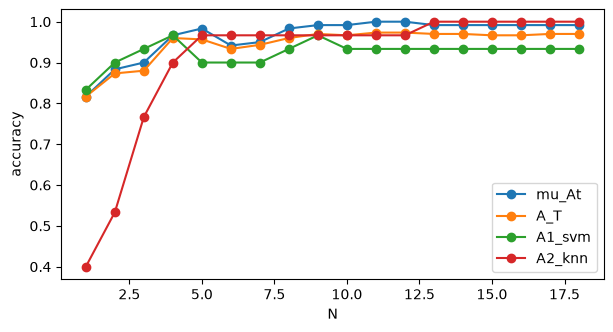

In [4]:
from pathlib import Path
p = sorted(Path('../results').glob('table5_gme_ann_splits*.csv'))
if p:
    t5 = pd.read_csv(p[-1]); display(t5.drop(columns='features'))
    ax = t5.plot(x='N', y=['mu_At', 'A_T', 'A1_svm', 'A2_knn'], marker='o', figsize=(7, 3.5)); ax.set_ylabel('accuracy'); plt.show()
else:
    print('run scripts/reproduce_tables.py first')